       INDIA TOURISM STATISTICS (2021) - ASI HERITAGE MONUMENT RANKING    
 National_Rank             Name of the Monument      Circle  Total_Footfall_2019_20  Foreign_Tourist_Ratio  Composite_Score
             1                        Taj Mahal        Agra                 5075125               0.127172        48.084308
             2                Baori at Abhaneri      Jaipur                  152553               0.561982        36.580564
             3                        Agra Fort        Agra                 2013676               0.191948        27.954486
             4            Itimad-ud-Daulah-Tomb        Agra                  215492               0.383736        25.771454
             5                 Sultanghari Tomb       Delhi                     536               0.011194        25.697160
             6                      Qutub Minar       Delhi                 2303464               0.110841        25.189838
             7                   Fatehpur Sikri        Ag

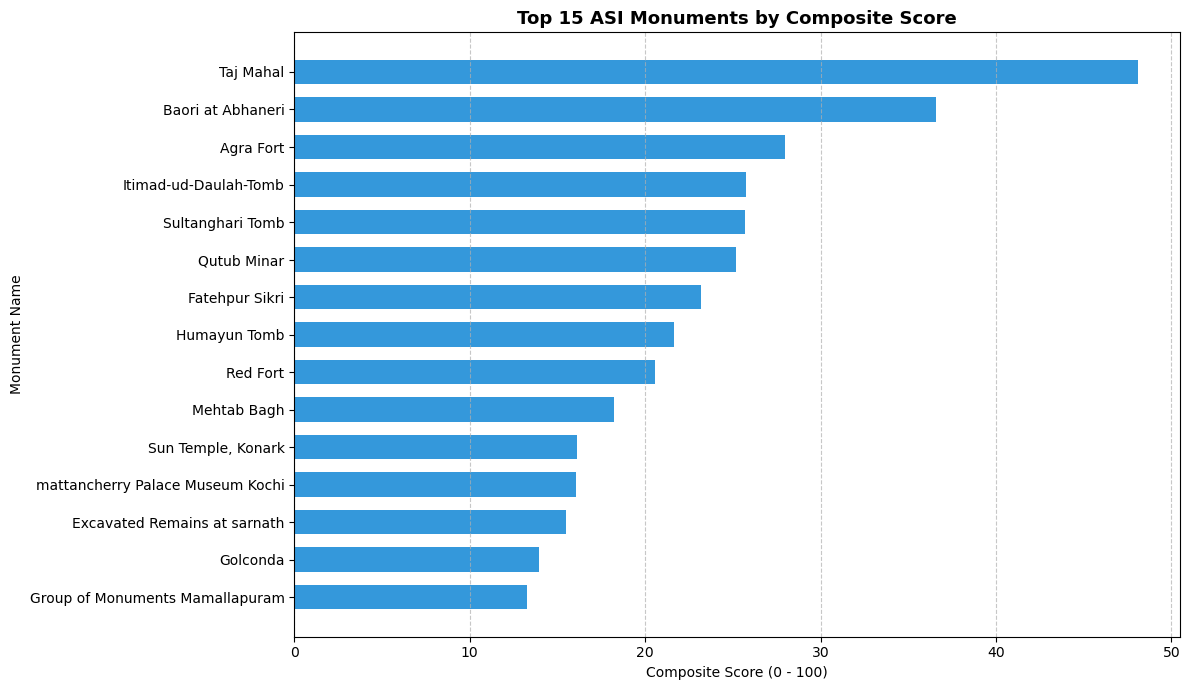

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# ==========================================
# 1. DIRECT DATASET IMPORT FROM DOWNLOADS
# ==========================================


df_raw = pd.read_csv('Downloads/India-Tourism-Statistics-2021-Table-5.2.3.csv')

# ==========================================
# 2. DATA CLEANING & PREPROCESSING
# ==========================================
df_clean = df_raw[
    ~df_raw['Circle'].astype(str).str.strip().isin(['Total', 'Grand Total']) &
    ~df_raw['Name of the Monument '].astype(str).str.strip().isin(['Total', 'Grand Total'])
].copy()

df_clean.columns = df_clean.columns.str.strip()
df_clean['Name of the Monument'] = df_clean['Name of the Monument'].str.strip()
df_clean['Circle'] = df_clean['Circle'].str.strip()

numeric_cols = ['Domestic-2019-20', 'Foreign-2019-20', 'Domestic-2020-21', 'Foreign-2020-21']
for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce').fillna(0)

# ==========================================
# 3. FEATURE ENGINEERING & RANKING
# ==========================================
df_clean['Total_Footfall_2019_20'] = df_clean['Domestic-2019-20'] + df_clean['Foreign-2019-20']
df_clean['Foreign_Tourist_Ratio'] = df_clean['Foreign-2019-20'] / (df_clean['Total_Footfall_2019_20'] + 1e-5)
df_clean['Domestic_Retention_Pct'] = (df_clean['Domestic-2020-21'] / (df_clean['Domestic-2019-20'] + 1e-5)) * 100
df_clean['Est_Revenue_INR'] = (df_clean['Domestic-2019-20'] * 50) + (df_clean['Foreign-2019-20'] * 600)

scaler = MinMaxScaler()
norm_features = scaler.fit_transform(
    df_clean[['Total_Footfall_2019_20', 'Foreign_Tourist_Ratio', 'Domestic_Retention_Pct']]
)

weights = np.array([0.40, 0.35, 0.25])
df_clean['Composite_Score'] = np.dot(norm_features, weights) * 100
df_clean = df_clean.sort_values(by='Composite_Score', ascending=False).reset_index(drop=True)
df_clean['National_Rank'] = df_clean.index + 1

top_15 = df_clean.head(15)
ellora_row = df_clean[df_clean['Name of the Monument'].str.contains('Ellora', case=False, na=False)].iloc[0]

# ==========================================
# 4. DISPLAY SUMMARY METRICS (FORCED FLUSH)
# ==========================================
print("==========================================================================", flush=True)
print("       INDIA TOURISM STATISTICS (2021) - ASI HERITAGE MONUMENT RANKING    ", flush=True)
print("==========================================================================", flush=True)
print(top_15[['National_Rank', 'Name of the Monument', 'Circle',
              'Total_Footfall_2019_20', 'Foreign_Tourist_Ratio', 'Composite_Score']].to_string(index=False), flush=True)

print("\n--------------------------------------------------------------------------", flush=True)
print(f"Monument Name          : {ellora_row['Name of the Monument']}", flush=True)
print(f"Circle                 : {ellora_row['Circle']}", flush=True)
print(f"National Rank          : #{int(ellora_row['National_Rank'])} out of {len(df_clean)} ASI Monuments", flush=True)
print(f"Total Footfall (19-20) : {int(ellora_row['Total_Footfall_2019_20']):,} visitors", flush=True)
print(f"Foreign Tourists       : {int(ellora_row['Foreign-2019-20']):,} visitors", flush=True)
print(f"Foreign Share Ratio    : {ellora_row['Foreign_Tourist_Ratio']:.2%}", flush=True)
print(f"Composite Score        : {ellora_row['Composite_Score']:.2f} / 100", flush=True)
print("--------------------------------------------------------------------------\n", flush=True)

# ==========================================
# 5. PURE MATPLOTLIB DASHBOARD
# ==========================================
plt.figure(figsize=(12, 7))

# Horizontal Bar Chart using pure Matplotlib
bar_colors = [
    '#e74c3c' if 'Ellora' in name else '#3498db'
    for name in top_15['Name of the Monument']
]

y_pos = np.arange(len(top_15))

plt.barh(
    y_pos,
    top_15['Composite_Score'],
    color=bar_colors,
    height=0.65
)

plt.yticks(
    y_pos,
    top_15['Name of the Monument'],
    fontsize=10
)

plt.gca().invert_yaxis()

plt.title(
    'Top 15 ASI Monuments by Composite Score',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('Composite Score (0 - 100)')
plt.ylabel('Monument Name')

plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

